# 08 Market conditions: does the required support survive other grid futures?

**Purpose.** This notebook tests whether the base-world findings about the required support hold
when the grid around the mandated SMR fleet changes. The Step 4 batch re-solves each of the 18
SMR-program runs (six target trajectories times three cost samples) in six alternative *market
conditions*, 108 runs in all. A market condition is one set of ReEDS switches that changes gas
prices, electricity demand, renewable costs or transmission expansion and leaves the nuclear
inputs alone. The notebook reads the *shadow price* of the nuclear capacity mandate in every run.
The shadow price (also called the dual) is the marginal system cost of one more MW of required
nuclear capacity in a solve year; the production runs carry no nuclear credit, so the shadow price
is the whole support the mandated fleet needs. The notebook then asks four questions, in order:
which mandated years still bind, whether the shape of the shadow-price path survives, whether the
ordering of the target trajectories survives, and how far the level moves.

**Inputs.**
- `results/exports/06a/step3_checks/{duals_by_year,overbuild_by_case}.csv` (18 reference runs)
  and `results/exports/06a/step4_checks/{duals_by_year,overbuild_by_case,switch_echo}.csv`
  (the 120 Step 4 runs), all from notebook 06a_run_tables_core.
- `results/exports/07/t04_bridge_metrics.csv` (notebook 07_required_support), for a regression
  tie on the reference column.
- `results/extracts/step4/nuclear_cap_price.parquet` (notebook 05_extract_reeds_outputs), for a
  spot check that the 06a table matches the model output.
- Casefile `cases_nuclearlearning_step4.csv` at the repository root.
- ReEDS inputs of this fork: `inputs/financials/{financials_sys_ATB2024,inflation_default}.csv`
  (the real discount rate).

**Outputs.** `results/exports/08/`: `s01_binding_shifts.csv`, `s02_shape_survival.csv`,
`s03_ranking_preservation.csv`, `s04_level_ratios.csv`, `s05_mechanism_color.csv`,
`market_condition_switches.csv`, and the panels `g01_binding_heatmap.png`,
`g02_shape_survival_matrix.png`, `g04_ranking_bump.png`, `g05_level_ratios.png`.
`results/figures/si/`: `SF13_market_capacity_expansion.png`, `SF23_shape_survival_matrix.png`.

**Paper items.** Supplementary Fig. 13 (g01, g05, g04), Supplementary Fig. 23 (g02),
Supplementary Table 14a–e (s01–s05; notebook 16 copies them to the table files).
No later analysis notebook reads the s-exports.

**Runtime.** About 20 s on the reference machine (4 threads).

In [1]:
import sys
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "nlpaper").is_dir():           # find z-ethan/ from wherever the kernel starts
    _p = _p.parent
sys.path.insert(0, str(_p))
import nlpaper
from nlpaper import paths, plotstyle as ps, h5io
nlpaper.setup(threads=4)

nlpaper setup: python 3.12.3 | numpy 1.26.4 | pandas 2.2.2 | matplotlib 3.8.4 | threads 4
determinism: seeds are explicit numpy Generators in each cell; results do not depend on PYTHONHASHSEED.


{'python': '3.12.3',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'threads': 4,
 'threadpoolctl': True,
 'env_set': {'OMP_NUM_THREADS': '4',
  'MKL_NUM_THREADS': '4',
  'OPENBLAS_NUM_THREADS': '4',
  'NUMEXPR_NUM_THREADS': '4',
  'NUMBA_NUM_THREADS': '4'},
 'matplotlib': '3.8.4',
 'seed_note': None}

## 1. The runs and the six market conditions

The Step 4 casefile holds 120 runs. 108 of them are the market-condition runs,
`smr100_{schedule}_{pct}_{condition}`. Each one copies an SMR-program reference run of the
`smr100` casefile and changes only the switches of its condition. The *reference case* of a run is
the `smr100_{schedule}_{pct}` run with ReEDS's default market inputs. The other 12 Step 4 runs are
large-reactor comparators at P5 and P95 in the reference market; notebook 07 reads them, and this
notebook ignores them.

A *target trajectory* (a `schedule` in the code: `eia`, `aj`, `iaea`, `mck`, `cop28`, `eo`, ordered
by 2050 ambition) is a national path of mandated SMR capacity from one published source. A *cost
sample* (`p05`, `p50`, `p95`) is one joint Monte Carlo draw of the nuclear cost world, at the P5,
P50 or P95 percentile of the discounted program cost.

The next cell reads the switch settings straight from the casefile, so the table below is the
definition of each condition. The six conditions are:

- **Low gas price** (`gaslo`): `ngscen = AEO_2026_HOG`, the AEO 2026 high oil-and-gas *supply*
  case, which gives a low gas price.
- **High gas price** (`gashi`): `ngscen = AEO_2026_LOG`, the low-supply case, which gives a high
  gas price.
- **High electricity demand** (`demhi`): `GSw_LoadProfiles = EER2025_100by2050`, the EER 2025
  load with 100 % electrification by 2050.
- **Low-cost renewables** (`relo`): the ATB 2024 *advanced* cost cases for utility PV, onshore and
  offshore wind, batteries, CSP and geothermal (plus low hydro cost, the `TI` geothermal
  discovery case and the low-RE distributed-PV scenario).
- **High-cost renewables** (`rehi`): the ATB 2024 *conservative* cost cases for the same
  technologies (plus the high-RE distributed-PV scenario).
- **Transmission-limited** (`translim`): `GSw_TransRestrict = transreg` (no new interregional
  lines outside the transmission regions) and `GSw_TransInvMaxLongTerm = 1.07` (a tighter
  long-term cap on annual transmission investment).

The switch echo of notebook 06a confirms that each condition moved its target variable in the
solved runs: the second table below gives, per condition, the run's gas price, load, renewable
cost or new transmission relative to its reference run.

In [2]:
import shutil

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau

pd.set_option("display.width", 200)

EXPORTS = paths.exports("08")
FIGURES = EXPORTS                      # the source panels live beside the tables
CHECKS3 = paths.exports("06a") / "step3_checks"
CHECKS4 = paths.exports("06a") / "step4_checks"
EXP07 = paths.exports("07")

# ---- case matrix ----------------------------------------------------------------
cases4 = pd.read_csv(paths.casefile("step4"), index_col=0)
CASES4 = [c for c in cases4.columns if c != "Default Value"]
assert len(CASES4) == 120, f"the step4 casefile holds 108 market-condition runs and 12 large100 runs: {len(CASES4)}"

SCHEDULES = ["eia", "aj", "iaea", "mck", "cop28", "eo"]      # ordered by 2050 ambition
PCTS = ["p05", "p50", "p95"]
SENS = ["gaslo", "gashi", "demhi", "relo", "rehi", "translim"]

# single source of truth for the condition names: every figure label derives from this.
SENS_META = {
    "gaslo":    dict(label="Low gas price",  note="AEO_2026_HOG: high oil & gas supply = LOW price"),
    "gashi":    dict(label="High gas price", note="AEO_2026_LOG: low oil & gas supply = HIGH price"),
    "demhi":    dict(label="High electricity demand", note="EER2025 100%-by-2050 electrification demand"),
    "relo":     dict(label="Low-cost renewables", note="ATB 2024 advanced RE + storage"),
    "rehi":     dict(label="High-cost renewables", note="ATB 2024 conservative RE + storage"),
    "translim": dict(label="Transmission-limited", note="GSw_TransRestrict=transreg + 1.07x cap; "
                                                       "read national aggregates only"),
}

def parse_case(c):
    "Split a case name into (family, schedule, percentile, condition)."
    fam = "large" if c.startswith("large100") else "smr"
    parts = c.split("_")
    sens = parts[3] if len(parts) > 3 else ""
    return fam, parts[1], parts[2], sens

SENS_CASES = [c for c in CASES4 if parse_case(c)[3] in SENS]
assert len(SENS_CASES) == 108, f"18 SMR runs x 6 market conditions = 108 runs: {len(SENS_CASES)}"
BASE_CASES = [f"smr100_{tok}_{p}" for tok in SCHEDULES for p in PCTS]
BASE_OF = {c: "_".join(c.split("_")[:3]) for c in SENS_CASES}

# analysis paths: each of the 18 reference runs plus its 6 market-condition variants.
ALL_PATHS = BASE_CASES + SENS_CASES
print(f"paths: {len(ALL_PATHS)} = 18 reference + 108 market-condition runs")

# ---- the switches each condition sets (read from the casefile) --------------------
BY_COND = {s: [c for c in SENS_CASES if parse_case(c)[3] == s] for s in SENS}
rows = []
for sw_name in cases4.index:
    sets = {s: frozenset(cases4.loc[sw_name, BY_COND[s]].dropna().astype(str)) for s in SENS}
    if len(set(sets.values())) == 1:
        continue                          # same in every condition: not a market switch
    for s in SENS:
        if sets[s]:
            assert len(sets[s]) == 1 and cases4.loc[sw_name, BY_COND[s]].notna().all(),                 f"{s}: switch {sw_name} must be set identically in all 18 runs of the condition"
            rows.append(dict(condition=s, label=SENS_META[s]["label"], switch=sw_name,
                             value=next(iter(sets[s]))))
SWITCHES = (pd.DataFrame(rows)
            .assign(_o=lambda d: d["condition"].map(SENS.index))
            .sort_values(["_o"], kind="stable").drop(columns="_o").reset_index(drop=True))
SWITCHES.to_csv(EXPORTS / "market_condition_switches.csv", index=False)
print(SWITCHES.to_string(index=False))

# ---- the switch echo: the solved runs moved as each condition intends ------------
echo = pd.read_csv(paths.require(CHECKS4 / "switch_echo.csv", "notebook 06a_run_tables_core"))
print()
print(echo.groupby(["sens", "metric"], sort=False)["value"]
      .agg(["count", "min", "median", "max"]).round(3).reindex(SENS, level=0))

paths: 126 = 18 reference + 108 market-condition runs
condition                   label                  switch                          value
    gaslo           Low gas price                  ngscen                   AEO_2026_HOG
    gashi          High gas price                  ngscen                   AEO_2026_LOG
    demhi High electricity demand        GSw_LoadProfiles              EER2025_100by2050
     relo     Low-cost renewables           plantchar_upv          upv_ATB_2024_advanced
     relo     Low-cost renewables       plantchar_onswind     ons-wind_ATB_2024_advanced
     relo     Low-cost renewables       plantchar_ofswind     ofs-wind_ATB_2024_advanced
     relo     Low-cost renewables       plantchar_battery      battery_ATB_2024_advanced
     relo     Low-cost renewables           plantchar_csp          csp_ATB_2024_advanced
     relo     Low-cost renewables           plantchar_geo          geo_ATB_2024_advanced
     relo     Low-cost renewables         plantchar_hydr

In [3]:
# ---- house figure style: nlpaper.plotstyle is the normative standard ---------------
# nlpaper.setup() already applied the house style (plotstyle.apply)
INK, MUTED = ps.INK, ps.MUTED
assert SCHEDULES == ps.SCHED_ORDER, "schedule tokens diverged from plotstyle.SCHED_ORDER"
SCHED_C = dict(ps.SCHED_C)
SENS_C = dict(ps.SENS_C)
SCHED_LABEL = dict(ps.SCHED_LABEL)      # the paper's target-trajectory names

def savefig(fig, name):
    return ps.savefig(fig, FIGURES / name)

## 2. The shadow-price table

The analysis starts from the per-year shadow-price tables of notebook 06a: the 18 reference runs
from `step3_checks/duals_by_year.csv` and the 108 market-condition runs from
`step4_checks/duals_by_year.csv`. The notebook never re-derives a shadow price. Set-equality
asserts guard the case coverage.

A mandated year is a solve year with a positive mandate. A mandated year *binds* when its shadow
price exceeds $1/MW-yr (in 2004 dollars, the unit ReEDS reports). A binding year is a year in which
the mandate, not the market, decides the nuclear build: without the mandate the model would build
less. The $1 threshold is the convention of the 06a checks; it separates true zeros from solver
noise.

**Units.** The exports keep the dollar columns of the source: 2004 dollars where the column name
says `2004` and 2024 dollars where it says `2024`. Every figure in this notebook shows a count, a
rank or a ratio, so no dollar year appears on a figure.

In [4]:
DUALS3 = pd.read_csv(paths.require(CHECKS3 / "duals_by_year.csv", "notebook 06a_run_tables_core"))
DUALS4 = pd.read_csv(paths.require(CHECKS4 / "duals_by_year.csv", "notebook 06a_run_tables_core"))
assert set(DUALS4["case"]) == set(CASES4), "the step4 shadow-price table must cover all 120 runs"
assert set(BASE_CASES) <= set(DUALS3["case"]), "the step3 shadow-price table must cover the 18 reference runs"

DUALS = pd.concat([DUALS3[DUALS3["case"].isin(BASE_CASES)],
                   DUALS4[DUALS4["case"].isin(SENS_CASES)]], ignore_index=True)
assert set(DUALS["case"]) == set(ALL_PATHS)

fam, sched, pct, sens = zip(*[parse_case(c) for c in DUALS["case"]])
DUALS["schedule"], DUALS["pct"], DUALS["sens"] = sched, pct, sens
DUALS["sens"] = DUALS["sens"].replace("", "base")
DUALS["mandated"] = DUALS["mandate_MW"] > 0
DUALS["binding"] = DUALS["dual_2004_MWyr"] > 1.0          # 06a binding convention ($1/MW-yr, 2004$)
YEARS_RUN = sorted(DUALS["t"].unique())
assert len(YEARS_RUN) == 16, f"the runs solve 16 years (2010 ... 2050): {YEARS_RUN}"

OVB4 = pd.read_csv(paths.require(CHECKS4 / "overbuild_by_case.csv", "notebook 06a_run_tables_core"))
OVB3 = pd.read_csv(paths.require(CHECKS3 / "overbuild_by_case.csv", "notebook 06a_run_tables_core"))
OVB = pd.concat([OVB3[OVB3["case"].isin(BASE_CASES)],
                 OVB4[OVB4["case"].isin(SENS_CASES)]], ignore_index=True)

ARMS = ["base"] + SENS
print(DUALS.groupby("sens", sort=False)["case"].nunique().reindex(ARMS))

sens
base        18
gaslo       18
gashi       18
demhi       18
relo        18
rehi        18
translim    18
Name: case, dtype: int64


The next cell checks two runs of the table against the model output itself: the
`nuclear_cap_price` extract of notebook 05 holds the shadow price exactly as ReEDS wrote it.

In [5]:
# ---- spot check: the 06a table matches the model output ---------------------------
NCP4 = h5io.load("step4", "nuclear_cap_price")
for c in ["smr100_eia_p50_gaslo", "smr100_eo_p95_translim"]:
    got = NCP4[NCP4["case"] == c].set_index("t")["Value"].astype(float)
    exp = DUALS[(DUALS["case"] == c) & (DUALS["dual_2004_MWyr"] > 0)] \
        .set_index("t")["dual_2004_MWyr"]
    j = pd.concat([got, exp], axis=1, keys=["model", "table"]).fillna(0.0)
    assert float((j["model"] - j["table"]).abs().max()) < 1e-9, \
        f"{c}: the 06a shadow-price table must equal the model's nuclear_cap_price"
    print(f"match: {c} ({len(j)} shadow-price years equal the model output)")

match: smr100_eia_p50_gaslo (5 shadow-price years equal the model output)
match: smr100_eo_p95_translim (10 shadow-price years equal the model output)


## 3. Binding-year shifts (s01, Supplementary Fig. 13a, Supplementary Table 14a)

Before any comparison of shape or level, the notebook asks whether the mandate still binds in
each market condition. A condition that removes binding years makes the market carry part of the
trajectory by itself: in those years the mandated fleet needs no support. A run with no binding
year at all would need no support in that condition, and its shape cell in Section 4 would be
undefined.

`s01` gives, per run, the number of mandated years, the number and list of binding years, the
change in the binding count against the reference run (`d_n_binding`), whether the binding set
changed, and the largest overbuild ratio (built nuclear capacity over the mandate; 06a).

In [6]:
# ---- s01: binding shifts against the reference run -------------------------------
rows = []
for c in ALL_PATHS:
    _, tok, p, s = parse_case(c)
    s = s or "base"
    d = DUALS[(DUALS["case"] == c) & DUALS["mandated"]]
    byrs = sorted(d[d["binding"]]["t"])
    rows.append(dict(case=c, schedule=tok, pct=p, sens=s,
                     n_mandated=int(d["mandated"].sum()), n_binding=len(byrs),
                     binding_years=" ".join(map(str, byrs)),
                     max_overbuild=float(OVB.set_index("case").loc[c, "max_overbuild_ratio"])))
s01 = pd.DataFrame(rows)
base_nb = s01[s01.sens == "base"].set_index(["schedule", "pct"])["n_binding"]
base_by = s01[s01.sens == "base"].set_index(["schedule", "pct"])["binding_years"]
s01["d_n_binding"] = [
    int(r.n_binding - base_nb.loc[(r.schedule, r.pct)]) for r in s01.itertuples()]
s01["binding_set_changed"] = [
    r.binding_years != base_by.loc[(r.schedule, r.pct)] for r in s01.itertuples()]
s01.to_csv(EXPORTS / "s01_binding_shifts.csv", index=False)

unbound = s01[(s01.n_binding == 0) & (s01.sens != "base")]
print(f"market-condition runs with no binding year: {len(unbound)}")
if len(unbound):
    print(unbound[["case", "schedule", "pct", "sens", "max_overbuild"]].to_string(index=False))
changed = s01[(s01.sens != "base") & s01.binding_set_changed]
print(f"runs whose binding-year set differs from the reference run: {len(changed)} of 108")
print(s01[s01.sens != 'base'].groupby('sens')['d_n_binding']
      .agg(['mean', 'min', 'max']).round(2).reindex(SENS))

market-condition runs with no binding year: 0
runs whose binding-year set differs from the reference run: 19 of 108


          mean  min  max
sens                    
gaslo     0.06    0    1
gashi    -1.56   -6    0
demhi    -0.67   -4    0
relo      0.06    0    1
rehi     -0.56   -3    0
translim -0.22   -3    0


**Panel g01 (Supplementary Fig. 13a): binding mandated years per run.** Rows are the 18
target-trajectory and cost-sample pairs; columns are the reference case and the six conditions.
Each cell counts the mandated years whose shadow price exceeds $1/MW-yr. A lower count than the
reference column means the condition lets the market carry those years.

The panel authors its type with `ps.fonts(12.40)`: it is composed into the 12.4-inch-wide
Supplementary Fig. 13 canvas, which the page shrinks to 6.5 inches, so this size prints at the
paper's type specification.

saved -> analysis\results\exports\08\g01_binding_heatmap.png


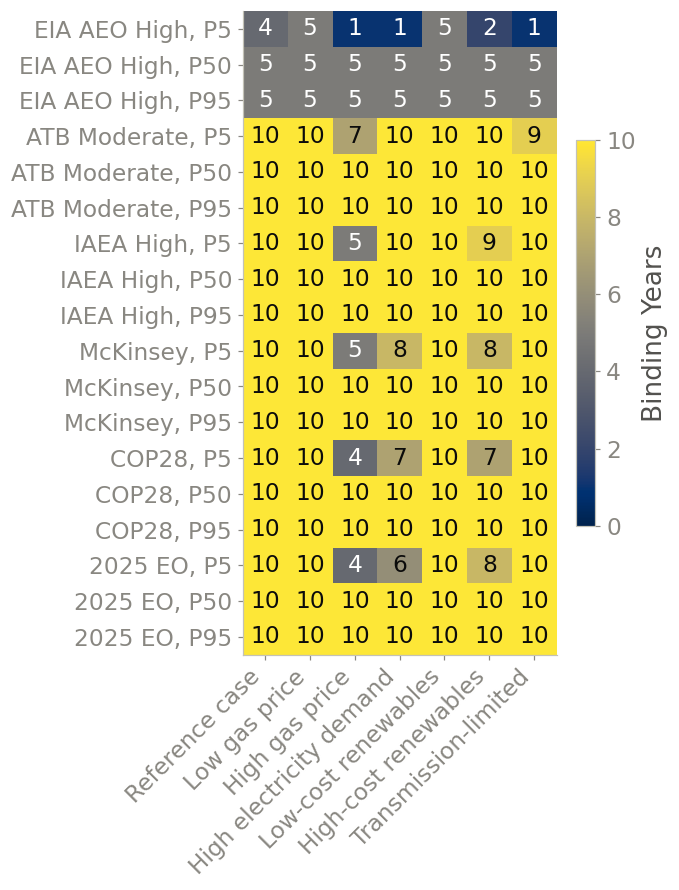

In [7]:
# ---- g01: binding-year-count heatmap (run x condition) ----------------------------
SI_CW = 12.40
F = ps.fonts(SI_CW)
CASE_ORDER = [(tok, p) for tok in SCHEDULES for p in PCTS]
M = np.full((len(CASE_ORDER), len(ARMS)), np.nan)
for i, (tok, p) in enumerate(CASE_ORDER):
    for j, s in enumerate(ARMS):
        row = s01[(s01.schedule == tok) & (s01.pct == p) & (s01.sens == s)]
        if len(row):
            M[i, j] = row.n_binding.iloc[0]

with mpl.rc_context(ps.font_rc(SI_CW)):
    fig, ax = plt.subplots(figsize=(4.6, 7.6))
    im = ax.imshow(M, cmap=ps.CMAP_SEQ, aspect="auto", vmin=0)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            ax.text(j, i, "-" if np.isnan(v) else f"{int(v)}", ha="center", va="center",
                    fontsize=F["annotation"], color="white" if v < np.nanmax(M) * 0.55 else INK)
    ax.set_xticks(range(len(ARMS)))
    # 45 degrees, not 30: at the larger type the parallel label lines collide at 30.
    ax.set_xticklabels(["Reference case"] + [SENS_META[s]["label"] for s in SENS],
                       rotation=45, ha="right")
    ax.set_yticks(range(len(CASE_ORDER)))
    ax.set_yticklabels([f"{ps.SCHED_SHORT[tok]}, {ps.PCT_SHORT[p]}" for tok, p in CASE_ORDER])
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, shrink=0.6)
    cb.set_label("Binding Years", size=F["axis_label"])
    cb.ax.tick_params(labelsize=F["tick"])
    savefig(fig, "g01_binding_heatmap.png")
plt.show()

## 4. Shape survival (s02, Supplementary Fig. 23, Supplementary Table 14b)

The base-world result that matters most is the *shape* of the shadow-price path: a bridge
subsidy should decay as the fleet moves down its learning curve. In the reference market the
decay holds in the P5 cost sample, holds weakly and unevenly at P50, and fails at P95, where the
shadow price does not come down by 2050. This section tests whether that pattern survives each
market condition.

The shape metrics per run are exactly those of notebook 07's `t04`: the peak year, the ratio of the
2050 shadow price to the peak (`end_over_peak`), the first year below half the peak, and the number
of mandated years with a zero shadow price. The *decay class* is a convention of this notebook:

- **unbound**: no binding mandated year (the cell is undefined).
- **decays**: the shadow price falls below half its peak by 2050 (a later binding year below half
  the peak, or a mandated year after the peak that no longer binds).
- **declines**: the 2050 shadow price sits below 0.95 times the peak but never falls below half.
- **flat**: the 2050 shadow price is at least 0.95 times the peak.

A cell *survives* when the run keeps its reference run's decay class, or when its end-over-peak
ratio moves by at most 0.15 from the reference run's. The test passes when the shape survives in
all 108 cells. The reference column must reproduce notebook 07's `t04` exactly; the cell asserts
that tie on all four metrics.

In [8]:
# ---- s02: shape metrics and survival ----------------------------------------------
def shape_metrics(c):
    d = DUALS[(DUALS["case"] == c) & DUALS["mandated"]].set_index("t").sort_index()
    b = d[d["binding"]]["dual_2004_MWyr"]
    if not len(b):
        return dict(peak_year=None, end_over_peak=None,
                    first_year_below_half_peak=None,
                    n_zero_dual_mandated_years=int((~d["binding"]).sum()),
                    n_binding=0, shape_class="unbound")
    peak_t, peak = int(b.idxmax()), float(b.max())
    end = float(d.loc[2050, "dual_2004_MWyr"]) if 2050 in d.index else 0.0
    below = [t for t in b.index if t > peak_t and b[t] < 0.5 * peak]
    zero_after = [t for t in d.index if t > peak_t and not d.loc[t, "binding"]]
    first_half = min(below + zero_after) if (below or zero_after) else None
    e = end / peak
    cls = "decays" if first_half is not None else ("flat" if e >= 0.95 else "declines")
    return dict(peak_year=peak_t, end_over_peak=round(e, 2),
                first_year_below_half_peak=first_half,
                n_zero_dual_mandated_years=int((~d["binding"]).sum()),
                n_binding=int(len(b)), shape_class=cls)

rows = []
for c in ALL_PATHS:
    _, tok, p, s = parse_case(c)
    rows.append(dict(case=c, schedule=tok, pct=p, sens=s or "base", **shape_metrics(c)))
s02 = pd.DataFrame(rows)

# regression tie: the reference column must reproduce notebook 07's t04 exactly.
t04 = pd.read_csv(paths.require(EXP07 / "t04_bridge_metrics.csv", "notebook 07_required_support")
                  ).set_index("case")
b02 = s02[s02.sens == "base"].set_index("case")
for c in BASE_CASES:
    assert abs(b02.loc[c, "end_over_peak"] - t04.loc[c, "end_over_peak"]) < 1e-9, c
    assert b02.loc[c, "peak_year"] == t04.loc[c, "peak_year"], c
    fh_b = b02.loc[c, "first_year_below_half_peak"]
    fh_t = t04.loc[c, "first_year_below_half_peak"]
    assert pd.isna(fh_b) == pd.isna(fh_t), c
    assert pd.isna(fh_b) or float(fh_b) == float(fh_t), c
    assert int(b02.loc[c, "n_zero_dual_mandated_years"]) == \
        int(t04.loc[c, "n_zero_dual_mandated_years"]), c
print("reference shape metrics reproduce notebook 07 t04 exactly (18 runs, all four metrics)")

base_m = s02[s02.sens == "base"].set_index(["schedule", "pct"])
s02["base_class"] = [base_m.loc[(r.schedule, r.pct), "shape_class"] for r in s02.itertuples()]
s02["d_end_over_peak"] = [
    (r.end_over_peak - base_m.loc[(r.schedule, r.pct), "end_over_peak"])
    if (r.end_over_peak is not None
        and base_m.loc[(r.schedule, r.pct), "end_over_peak"] is not None) else None
    for r in s02.itertuples()]
s02["peak_year_shift"] = [
    (r.peak_year - base_m.loc[(r.schedule, r.pct), "peak_year"])
    if (r.peak_year is not None
        and pd.notna(base_m.loc[(r.schedule, r.pct), "peak_year"])) else None
    for r in s02.itertuples()]
s02["survives"] = [
    None if r.sens == "base" else
    ("undefined" if r.shape_class == "unbound" else
     ("yes" if (r.shape_class == r.base_class
                or (r.d_end_over_peak is not None and abs(r.d_end_over_peak) <= 0.15))
      else "no"))
    for r in s02.itertuples()]
s02.to_csv(EXPORTS / "s02_shape_survival.csv", index=False)

sv = s02[s02.sens != "base"]
print(sv.groupby("sens")["survives"].value_counts().unstack(fill_value=0).reindex(SENS))
print("\nclass transitions (reference -> condition) that break survival:")
brk = sv[sv.survives == "no"]
print(brk.groupby(["base_class", "shape_class"])["case"].count() if len(brk) else "none")
n_surv = int((sv.survives == "yes").sum())
print(f"\nshape survives in {n_surv} of {len(sv)} cells")
assert n_surv == 108, f"the paper reports that the shape survives in 108 of 108 cells; here {n_surv}"

reference shape metrics reproduce notebook 07 t04 exactly (18 runs, all four metrics)
survives  yes
sens         
gaslo      18
gashi      18
demhi      18
relo       18
rehi       18
translim   18

class transitions (reference -> condition) that break survival:
none

shape survives in 108 of 108 cells


**Panel g02 (Supplementary Fig. 23): the shape-survival matrix.** Each cell shows the 2050 shadow
price over the run's peak shadow price. The glyph after the number is the decay class; the key
sits above the matrix because it decodes the cell text. The figure is placed on its own, 7.13
inches wide, so it authors its type with `ps.fonts(7.13)`. Supplementary Fig. 23 is this panel
unchanged; the cell copies it to `results/figures/si/`.

saved -> analysis\results\exports\08\g02_shape_survival_matrix.png


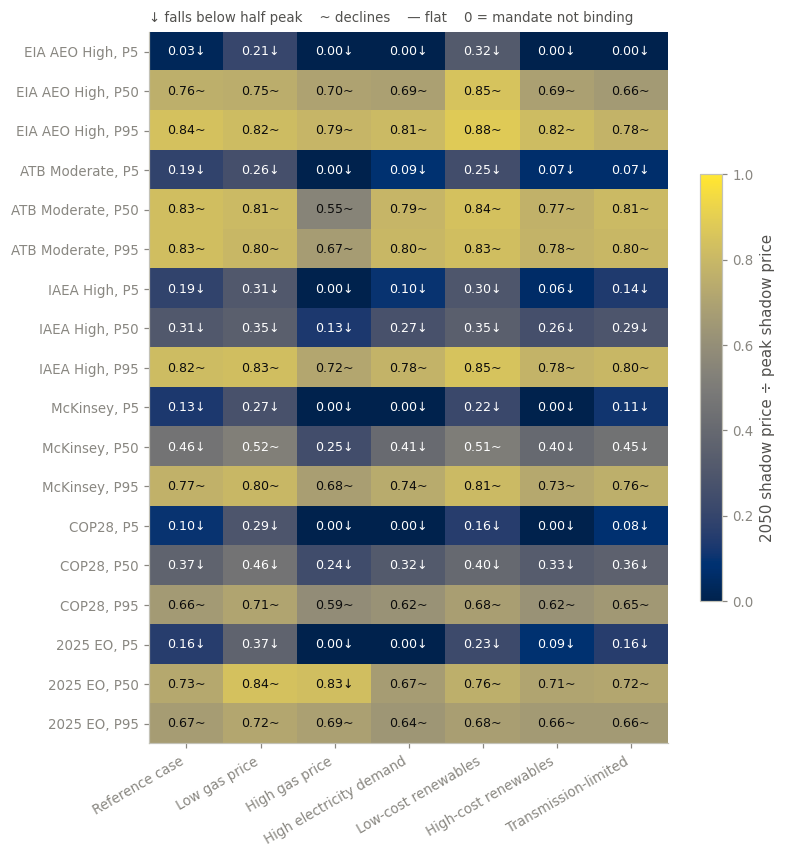

Supplementary Fig. 23 -> analysis\results\figures\si\SF23_shape_survival_matrix.png


In [9]:
# ---- g02: survival matrix (Supplementary Fig. 23) ---------------------------------
SI_CW = 7.13
F = ps.fonts(SI_CW)
M = np.full((len(CASE_ORDER), len(ARMS)), np.nan)
CLS = np.empty((len(CASE_ORDER), len(ARMS)), dtype=object)
for i, (tok, p) in enumerate(CASE_ORDER):
    for j, s in enumerate(ARMS):
        row = s02[(s02.schedule == tok) & (s02.pct == p) & (s02.sens == s)]
        if len(row):
            CLS[i, j] = row.shape_class.iloc[0]
            if row.end_over_peak.iloc[0] is not None:
                M[i, j] = row.end_over_peak.iloc[0]

with mpl.rc_context(ps.font_rc(SI_CW)):
    fig, ax = plt.subplots(figsize=(7.6, 8.4))
    im = ax.imshow(M, cmap=ps.CMAP_SEQ, aspect="auto", vmin=0.0, vmax=1.0)
    GLYPH = {"decays": "↓", "declines": "~", "flat": "—", "unbound": ""}
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if CLS[i, j] == "unbound":
                ax.text(j, i, "0", ha="center", va="center", fontsize=F["annotation"],
                        color=MUTED)
                continue
            v = M[i, j]
            # cividis: low values are dark blue (white text), high values light yellow (ink).
            ax.text(j, i, f"{v:.2f}{GLYPH[CLS[i, j]]}", ha="center", va="center",
                    fontsize=F["annotation"] * 0.94, color="white" if v < 0.55 else INK)
    # glyph key must live in the saved figure: it decodes the cell text.
    ax.text(0.0, 1.01, "↓ falls below half peak    ~ declines    — flat    "
            "0 = mandate not binding", transform=ax.transAxes,
            fontsize=F["annotation"], color=MUTED, ha="left", va="bottom")
    ax.set_xticks(range(len(ARMS)))
    ax.set_xticklabels(["Reference case"] + [SENS_META[s]["label"] for s in SENS],
                       rotation=30, ha="right")
    ax.set_yticks(range(len(CASE_ORDER)))
    ax.set_yticklabels([f"{ps.SCHED_SHORT[tok]}, {ps.PCT_SHORT[p]}" for tok, p in CASE_ORDER])
    ax.grid(False)
    cb = fig.colorbar(im, ax=ax, shrink=0.6)
    cb.set_label("2050 shadow price ÷ peak shadow price", size=F["axis_label"])
    cb.ax.tick_params(labelsize=F["tick"])
    g02_png = savefig(fig, "g02_shape_survival_matrix.png")
plt.show()

paths.FIGS_SI.mkdir(parents=True, exist_ok=True)
sf23 = shutil.copyfile(g02_png, paths.FIGS_SI / "SF23_shape_survival_matrix.png")
print(f"Supplementary Fig. 23 -> {paths.rel(sf23)}")

## 5. Ranking preservation (s03, Supplementary Fig. 13c, Supplementary Table 14c)

Within each market condition and cost sample, the six target trajectories are ranked from
cheapest to dearest on two scalars:

- the **mean binding shadow price**: the mean of the shadow price over the run's binding years
  (2024 $/MW-yr);
- the **discounted program bill**: the sum over solve years of the shadow price times the mandated
  capacity, discounted to 2026, in billions of 2024 dollars. This is the fiscal object: what a
  support program would pay in total. It does not depend on how many years bind.

*Kendall's tau* (a rank-agreement score from −1 to 1; 1 means the same order) compares each
ordering with the reference case's ordering in the same cost sample. With six trajectories there
are only 15 pairs, so tau moves in coarse steps; `s03` therefore also exports the raw orderings and
the list of swapped pairs.

**Discount rate.** The bill discounts at the ReEDS system real rate for 2026 onward, `DR` = 1.0536
(5.36 % per year): the after-tax nominal weighted cost of capital divided by inflation, averaged over
2026–2050. Notebook 07 uses the same rate.

In [10]:
# ---- real discount rate (same derivation as notebook 07) --------------------------
FIN_DIR = paths.reeds_inputs() / "financials"
sys_fin = pd.read_csv(FIN_DIR / "financials_sys_ATB2024.csv")
infl = pd.read_csv(FIN_DIR / "inflation_default.csv")
sys_fin = sys_fin.merge(infl, on="t", how="left")
sys_fin["d_nom"] = ((1 - sys_fin["debt_fraction"]) * (sys_fin["rroe_nom"] - 1)
                    + sys_fin["debt_fraction"] * (sys_fin["interest_rate_nom"] - 1)
                      * (1 - sys_fin["tax_rate"]) + 1)
sys_fin["d_real"] = sys_fin["d_nom"] / sys_fin["inflation_rate"]
dr_s = sys_fin.set_index("t")["d_real"].reindex(range(1990, 2051)).ffill()
DR = float(dr_s.loc[2026:2050].mean())
assert round(DR, 4) == 1.0536, f"the post-2026 ReEDS system real discount rate is 1.0536: {DR}"
print(f"DR = {DR:.4f} (post-2026 system real rate, as in notebook 07)")

# ---- s03: ranking preservation ----------------------------------------------------
def scalars(c):
    d = DUALS[(DUALS["case"] == c) & DUALS["mandated"]]
    b = d[d["binding"]]
    mean_dual = float(b["dual_2024_MWyr"].mean()) if len(b) else 0.0
    disc = (d["dual_2024_MWyr"] * d["mandate_MW"]
            / DR ** (d["t"] - 2026)).sum() / 1e9
    return mean_dual, float(disc)

SC = {c: scalars(c) for c in ALL_PATHS}
rows = []
for s in ARMS:
    for p in PCTS:
        for met_i, met in enumerate(["mean_binding_dual", "disc_program_bill"]):
            vals = {}
            for tok in SCHEDULES:
                c = f"smr100_{tok}_{p}" + ("" if s == "base" else f"_{s}")
                vals[tok] = SC[c][met_i]
            order = sorted(SCHEDULES, key=lambda k: vals[k])
            rows.append(dict(sens=s, pct=p, metric=met,
                             order_cheap_to_dear=" ".join(order),
                             **{f"v_{tok}": round(vals[tok], 3) for tok in SCHEDULES}))
s03 = pd.DataFrame(rows)

base_ord = s03[s03.sens == "base"].set_index(["pct", "metric"])["order_cheap_to_dear"]
taus, swaps = [], []
for r in s03.itertuples():
    bo = base_ord.loc[(r.pct, r.metric)].split()
    so = r.order_cheap_to_dear.split()
    tau = kendalltau([bo.index(t) for t in SCHEDULES],
                     [so.index(t) for t in SCHEDULES]).statistic
    sw = [(a, b) for i, a in enumerate(SCHEDULES) for b in SCHEDULES[i + 1:]
          if (bo.index(a) < bo.index(b)) != (so.index(a) < so.index(b))]
    taus.append(round(float(tau), 3))
    swaps.append("; ".join(f"{a}<->{b}" for a, b in sw) if sw else "")
s03["kendall_tau_vs_base"] = taus
s03["pairwise_swaps_vs_base"] = swaps
s03.to_csv(EXPORTS / "s03_ranking_preservation.csv", index=False)

sub = s03[s03.sens != "base"]
print(sub.groupby(["metric"])["kendall_tau_vs_base"].agg(["min", "mean"]).round(3))
n_sw = (sub.pairwise_swaps_vs_base != "").groupby(sub.metric).sum()
print(f"\ncells (condition x cost sample) whose ordering differs from the reference, of 18 each:")
print(n_sw.to_string())
print()
print(sub[sub.pairwise_swaps_vs_base != ''][
    ["sens", "pct", "metric", "kendall_tau_vs_base", "pairwise_swaps_vs_base"]]
    .to_string(index=False))

DR = 1.0536 (post-2026 system real rate, as in notebook 07)


                   min   mean
metric                       
disc_program_bill  1.0  1.000
mean_binding_dual  0.2  0.808

cells (condition x cost sample) whose ordering differs from the reference, of 18 each:
metric
disc_program_bill     0
mean_binding_dual    13

    sens pct            metric  kendall_tau_vs_base                                                pairwise_swaps_vs_base
   gaslo p05 mean_binding_dual                0.867                                                            cop28<->eo
   gaslo p50 mean_binding_dual                0.867                                                              eia<->eo
   gaslo p95 mean_binding_dual                0.867                                                             iaea<->eo
   gashi p05 mean_binding_dual                0.600                                  iaea<->cop28; iaea<->eo; mck<->cop28
   gashi p50 mean_binding_dual                0.867                                                              eia<->eo
   g

**Panel g04 (Supplementary Fig. 13c): the ranking bump chart.** One panel per cost sample. Each
line is one target trajectory; its height is the trajectory's rank by **mean binding shadow price**
(1 = lowest) in each market condition. A flat line means the ordering survives that condition.
The panel draws the mean-binding-shadow-price metric, the one that moves; the fiscal-bill ordering
is in `s03` and, per the cell above, does not change in any cell.

saved -> analysis\results\exports\08\g04_ranking_bump.png


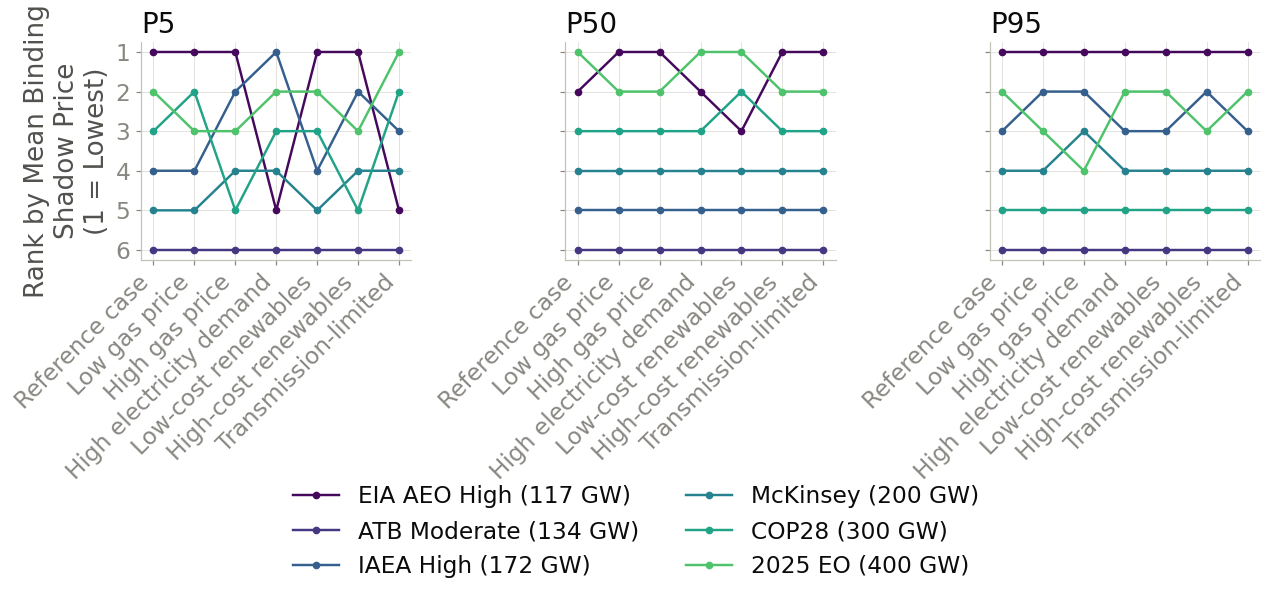

In [11]:
# ---- g04: bump chart of trajectory ranks ------------------------------------------
SI_CW = 12.40
F = ps.fonts(SI_CW)
with mpl.rc_context(ps.font_rc(SI_CW)):
    fig, axes = plt.subplots(1, 3, figsize=(11.8, 5.6), sharey=True)
    for ax, p in zip(axes, PCTS):
        for tok in SCHEDULES:
            ys = []
            for s in ARMS:
                o = s03[(s03.sens == s) & (s03.pct == p)
                        & (s03.metric == "mean_binding_dual")].order_cheap_to_dear.iloc[0].split()
                ys.append(o.index(tok) + 1)
            ax.plot(range(len(ARMS)), ys, marker="o", ms=4, color=SCHED_C[tok],
                    lw=1.6, label=SCHED_LABEL[tok])
        ax.set_xticks(range(len(ARMS)))
        # 45 degrees, not 30: the parallel label lines collide at 30 at this type size.
        ax.set_xticklabels(["Reference case"] + [SENS_META[s]["label"] for s in SENS],
                           rotation=45, ha="right", fontsize=F["tick"])
        ax.set_title(ps.PCT_SHORT[p], fontsize=F["panel_title"])
        ax.invert_yaxis()
        ax.set_yticks(range(1, 7))
    # the y label wraps onto three lines: one line of it is twice the height of the panel.
    axes[0].set_ylabel("Rank by Mean Binding\nShadow Price\n(1 = Lowest)",
                       fontsize=F["axis_label"])
    # figure-level legend below the panels, in a band of its own.
    h04, l04 = axes[0].get_legend_handles_labels()
    fig.legend(h04, l04, loc="lower center", ncol=2, fontsize=F["legend"],
               bbox_to_anchor=(0.5, 0.005))
    fig.tight_layout(rect=(0, 0.15, 1, 1))
    savefig(fig, "g04_ranking_bump.png")
plt.show()

## 6. Level ratios (s04, Supplementary Fig. 13b, Supplementary Table 14d)

The level is the weakest layer of the test: it tells how far the support moves, not whether its
shape or order survives. For each market-condition run the *level ratio* is its mean shadow price
over its reference run's mean shadow price. The headline ratio (`ratio_shared`) compares like for
like: both means run over the years in which *both* runs bind, so a condition that removes a
binding year does not shift the ratio just by dropping that year. The companion ratio
(`ratio_own`) takes each run's mean over its own binding years. An empty intersection would leave
`ratio_shared` blank and point back to Section 3.

The notebook does not recompute a required credit rate per condition. The nuclear financing inputs
of every market-condition run equal those of its reference run (06a check B1), so for a given run
and year the conversion from shadow price to credit rate is the same linear map. Rate shifts
therefore follow the ratios below, up to the binding-year changes that `s01` reports. Every number
here is national; the transmission-limited condition in particular is read only as a national
aggregate.

In [12]:
# ---- s04: level ratios against the reference run ----------------------------------
rows = []
for c in SENS_CASES:
    _, tok, p, s = parse_case(c)
    b = BASE_OF[c]
    dc = DUALS[(DUALS["case"] == c) & DUALS["binding"]].set_index("t")["dual_2024_MWyr"]
    db = DUALS[(DUALS["case"] == b) & DUALS["binding"]].set_index("t")["dual_2024_MWyr"]
    inter = sorted(set(dc.index) & set(db.index))
    rows.append(dict(
        case=c, schedule=tok, pct=p, sens=s, n_shared_binding=len(inter),
        ratio_shared=round(float(dc.reindex(inter).mean() / db.reindex(inter).mean()), 3)
        if inter else None,
        ratio_own=round(float(dc.mean() / db.mean()), 3)
        if len(dc) and len(db) else None))
s04 = pd.DataFrame(rows)
s04.to_csv(EXPORTS / "s04_level_ratios.csv", index=False)

print(s04.groupby("sens")["ratio_shared"]
      .agg(["count", "min", "median", "max"]).round(3).reindex(SENS))
empty = s04[s04.n_shared_binding == 0]
if len(empty):
    print(f"\nempty binding-year intersection (see Section 3): {list(empty.case)}")

          count    min  median    max
sens                                 
gaslo        18  1.090   1.182  1.768
gashi        18  0.347   0.725  0.866
demhi        18  0.772   0.916  0.965
relo         18  1.043   1.092  1.682
rehi         18  0.613   0.905  0.956
translim     18  0.802   0.948  0.984


**Panel g05 (Supplementary Fig. 13b): level ratios by market condition.** One dot per run: its
mean binding shadow price over the reference run's, on the shared binding years. The marker shape
encodes the cost sample, and the ink bar marks the condition's median. The dotted line at 1 means
no shift. The horizontal jitter uses a fixed seed, printed by the cell.

g05 jitter seed = 20260715


saved -> analysis\results\exports\08\g05_level_ratios.png


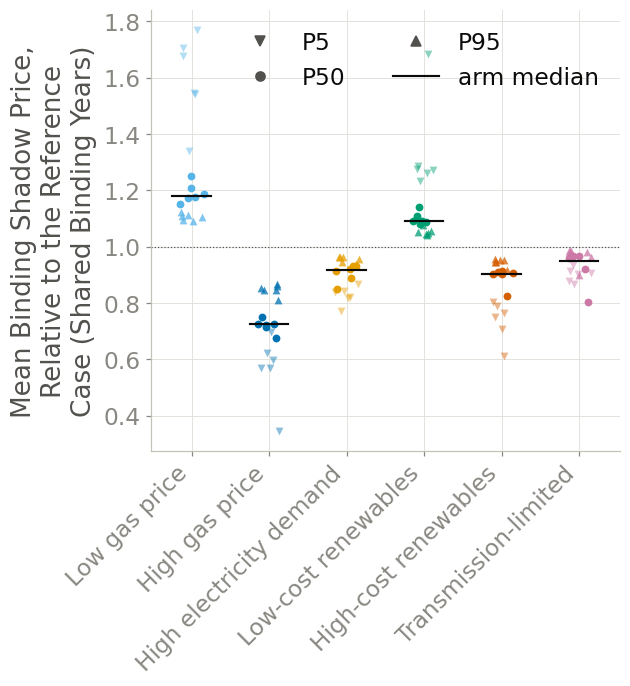

In [13]:
# ---- g05: level-ratio dot plot ----------------------------------------------------
from matplotlib.lines import Line2D

SEED_G05 = 20260715          # horizontal jitter only; no number depends on it
print(f"g05 jitter seed = {SEED_G05}")
SI_CW = 12.40
F = ps.fonts(SI_CW)
with mpl.rc_context(ps.font_rc(SI_CW)):
    fig, ax = plt.subplots(figsize=(5.5, 5.2))
    rng = np.random.default_rng(SEED_G05)
    for j, s in enumerate(SENS):
        sub = s04[(s04.sens == s) & s04.ratio_shared.notna()]
        x = j + rng.uniform(-0.16, 0.16, len(sub))
        for (xi, r) in zip(x, sub.itertuples()):
            ax.scatter(xi, r.ratio_shared, s=26, color=SENS_C[s],
                       alpha={"p05": 0.45, "p50": 1.0, "p95": 0.75}[r.pct],
                       marker={"p05": "v", "p50": "o", "p95": "^"}[r.pct], lw=0)
        med = sub.ratio_shared.median()
        ax.plot([j - 0.25, j + 0.25], [med, med], color=INK, lw=1.4)
    ax.axhline(1.0, color=MUTED, lw=0.8, ls=":")
    ax.set_xticks(range(len(SENS)))
    ax.set_xticklabels([SENS_META[s]["label"] for s in SENS], rotation=45, ha="right")
    ax.set_ylabel("Mean Binding Shadow Price,\nRelative to the Reference\nCase (Shared Binding Years)",
                  fontsize=F["axis_label"])
    # marker key must live in the saved figure: it decodes the dot shapes.
    handles = ([Line2D([], [], marker=m, ls="", color=MUTED, label=p)
                for p, m in [(ps.PCT_SHORT["p05"], "v"), (ps.PCT_SHORT["p50"], "o"),
                             (ps.PCT_SHORT["p95"], "^")]]
               + [Line2D([], [], color=INK, lw=1.4, label="arm median")])
    ax.legend(handles=handles, fontsize=F["legend"], ncol=2, loc="best")
    savefig(fig, "g05_level_ratios.png")
plt.show()

## 7. Mechanism check (s05, Supplementary Table 14e)

This check asks whether each condition moves the level in the direction economics predicts. The
mandate fixes the nuclear build, so the shadow price moves against the *market value* of the
mandated capacity. A condition that lowers energy and capacity prices (cheap gas, cheap renewables)
should raise the required support (median ratio above 1). A condition that raises them (dear gas,
dear renewables, higher demand) should lower it (median ratio below 1). Transmission limits cut
both ways, local scarcity against delivery constraints, so that condition carries no prior. A
condition whose median goes against its prior would be flagged `SURPRISE`; the check reports and
does not adjudicate.

In [14]:
PRIOR = {"gaslo": ">1", "gashi": "<1", "demhi": "<1",
         "relo": ">1", "rehi": "<1", "translim": "none"}
rows = []
for s in SENS:
    sub = s04[(s04.sens == s) & s04.ratio_shared.notna()]
    frac_up = float((sub.ratio_shared > 1.0).mean())
    med = float(sub.ratio_shared.median())
    pr = PRIOR[s]
    if pr == "none":
        verdict = "no prior"
    else:
        agrees = (med > 1.0) if pr == ">1" else (med < 1.0)
        verdict = "agrees" if agrees else "SURPRISE"
    rows.append(dict(sens=s, prior=pr, median_ratio=round(med, 3),
                     frac_cases_above_1=round(frac_up, 2), verdict=verdict))
s05 = pd.DataFrame(rows)
print(s05.to_string(index=False))
s05.to_csv(EXPORTS / "s05_mechanism_color.csv", index=False)

    sens prior  median_ratio  frac_cases_above_1  verdict
   gaslo    >1         1.181                 1.0   agrees
   gashi    <1         0.725                 0.0   agrees
   demhi    <1         0.916                 0.0   agrees
    relo    >1         1.091                 1.0   agrees
    rehi    <1         0.905                 0.0   agrees
translim  none         0.948                 0.0 no prior


## 8. Supplementary Fig. 13: composition

Supplementary Fig. 13 pastes three panels at their native pixels, without redrawing: g01 (a) and
g05 (b) in the first row, g04 (c) in the second row, centred. The panel letters are 10 pt printed;
the composed canvas is about 12.4 inches wide, so they are stamped at `ps.fonts(12.36)`
points, the width the SI layout measured for this figure.

composed -> analysis\results\figures\si\SF13_market_capacity_expansion.png  (3707x4199 px)


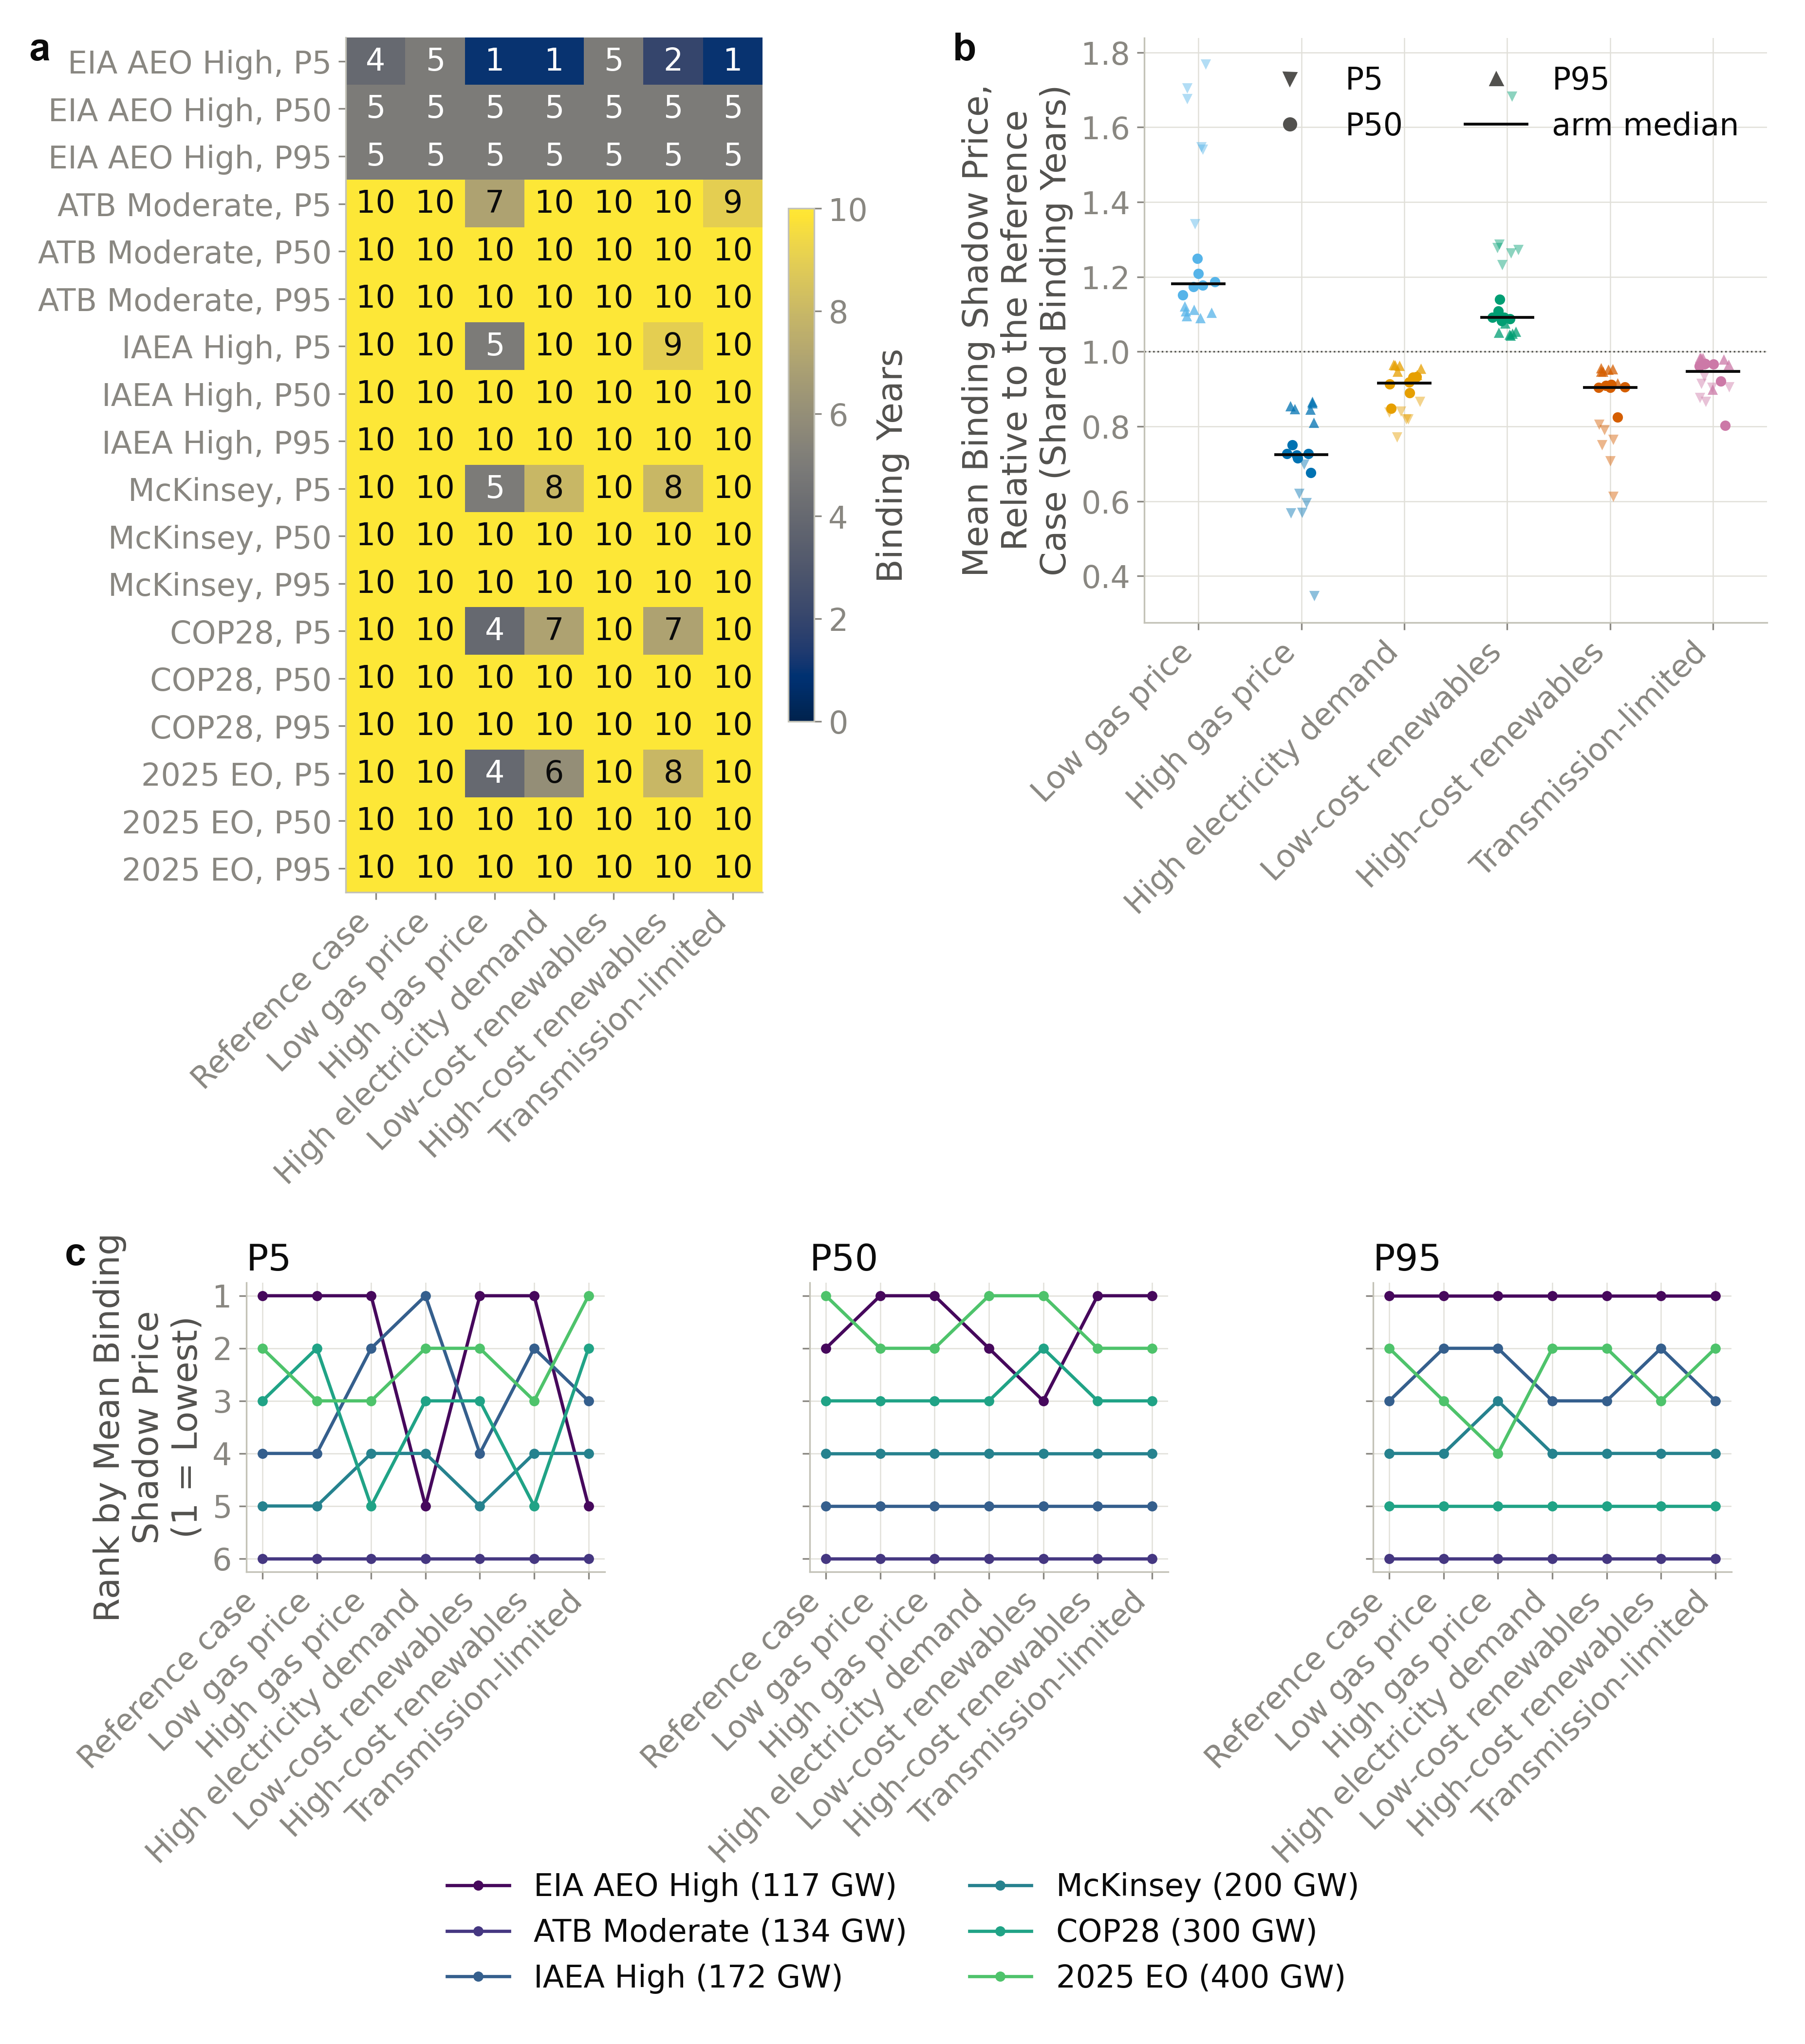

In [15]:
from nlpaper.compose import compose

sf13 = compose([[FIGURES / "g01_binding_heatmap.png", FIGURES / "g05_level_ratios.png"],
                [FIGURES / "g04_ranking_bump.png"]],
               "SF13_market_capacity_expansion.png", letters="abc", center=True,
               letter_pt=ps.fonts(12.36)["panel_letter"], out_dir=paths.FIGS_SI)

## 9. Caveats

- **National readouts only.** Regional and transmission readouts are not comparable across cost
  worlds, because the model's siting of the mandated fleet is degenerate between regions. Every
  number here is national. This caveat binds hardest for the transmission-limited condition.
- **Myopic runs.** All runs solve one year at a time (sequential, myopic foresight); the shadow
  prices are per-year rental prices.
- **Cross-trajectory levels mix cost worlds.** Each trajectory's cost samples are different Monte
  Carlo draws, so level comparisons across trajectories are descriptive, not causal.
- **Runs with no binding year** would mean "needs no support in this condition", not "no decay";
  their shape cells are undefined by construction. None occurs here.
- **Thresholds are conventions.** The half-peak test, the 0.95 flat cut and the 0.15 survival band
  are this notebook's conventions; `s02` exports the metrics so a reader can re-cut them.

In [16]:
manifest = sorted(p.name for p in EXPORTS.glob("*.csv")) \
    + sorted(p.name for p in FIGURES.glob("g0*.png")) \
    + [paths.rel(p).as_posix() for p in sorted(paths.FIGS_SI.glob("SF[12]3_*.png"))]
print("outputs written by this notebook:")
for m in manifest:
    print(" ", m)

outputs written by this notebook:
  market_condition_switches.csv
  s01_binding_shifts.csv
  s02_shape_survival.csv
  s03_ranking_preservation.csv
  s04_level_ratios.csv
  s05_mechanism_color.csv
  g01_binding_heatmap.png
  g02_shape_survival_matrix.png
  g04_ranking_bump.png
  g05_level_ratios.png
  analysis/results/figures/si/SF13_market_capacity_expansion.png
  analysis/results/figures/si/SF23_shape_survival_matrix.png
